In [18]:


import numpy as np
import pandas as pd

# Visualization
import matplotlib.pyplot as plt
import seaborn as sns

# Preprocessing
from sklearn.base import BaseEstimator, TransformerMixin
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import (
    StandardScaler,
    OrdinalEncoder,
    OneHotEncoder
)

# Train-test split
from sklearn.model_selection import (
    train_test_split,
    StratifiedKFold,
    RepeatedStratifiedKFold,
    GridSearchCV,
    cross_validate
)

# Models
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import (
    RandomForestClassifier,
    HistGradientBoostingClassifier
)

# Clustering
from sklearn.cluster import KMeans
from sklearn.metrics import (
    silhouette_score,
    adjusted_rand_score
)

# Classification metrics
from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    f1_score,
    roc_auc_score,
    log_loss,
    confusion_matrix,
    classification_report,
    cohen_kappa_score
)



SEED = 42

TARGET = "diabetes_risk"

CLASSES = [
    "Low",
    "Medium",
    "High"
]

np.random.seed(SEED)

In [12]:


df = pd.read_csv(r"C:\Users\harsh\Downloads\diabetes_risk.csv")

print("Dataset shape:", df.shape)

print("\nFirst 5 rows:")
display(df.head())

print("\nColumn names:")
print(df.columns.tolist())

print("\nData types:")
print(df.dtypes)

print("\nMissing values:")
print(df.isnull().sum())

Dataset shape: (15000, 19)

First 5 rows:


,patient_id,age,gender,city,bmi,family_history_diabetes,physical_activity_level,diet_type,smoking_status,alcohol_consumption,hours_sleep_per_night,stress_level,fasting_blood_sugar,hba1c_level,blood_pressure_systolic,blood_pressure_diastolic,waist_circumference_cm,income_bracket,diabetes_risk
0,1,47,Female,Mumbai,26.5,Yes,Sedentary,Vegetarian,Never,Never,9.0,8,178,7.3,146,90,107.1,High,Low
1,2,53,Female,Mumbai,20.5,Yes,Moderate,Vegetarian,Never,Never,7.0,6,152,6.9,156,100,93.8,Low,Low
2,3,47,Male,Thane,31.3,No,Moderate,Non-Vegetarian,Current,Regular,7.0,7,168,6.6,150,102,113.5,Low,High
3,4,41,Male,Bengaluru,22.8,No,Sedentary,Non-Vegetarian,Never,Never,9.0,5,155,6.7,126,92,109.6,Middle,Low
4,5,57,Female,Bengaluru,16.7,No,Sedentary,Non-Vegetarian,Current,Occasional,6.5,10,188,6.7,130,90,80.8,High,Low



Column names:
['patient_id', 'age', 'gender', 'city', 'bmi', 'family_history_diabetes', 'physical_activity_level', 'diet_type', 'smoking_status', 'alcohol_consumption', 'hours_sleep_per_night', 'stress_level', 'fasting_blood_sugar', 'hba1c_level', 'blood_pressure_systolic', 'blood_pressure_diastolic', 'waist_circumference_cm', 'income_bracket', 'diabetes_risk']

Data types:
patient_id                    int64
age                           int64
gender                       object
city                         object
bmi                         float64
family_history_diabetes      object
physical_activity_level      object
diet_type                    object
smoking_status               object
alcohol_consumption          object
hours_sleep_per_night       float64
stress_level                  int64
fasting_blood_sugar           int64
hba1c_level                 float64
blood_pressure_systolic       int64
blood_pressure_diastolic      int64
waist_circumference_cm      float64
income_bra

In [13]:
df = df.drop(columns=["patient_id"])

print("Shape after removing patient_id:", df.shape)

Shape after removing patient_id: (15000, 18)


In [20]:
print("Dataset information:")
df.info()

print("\nTarget distribution:")
print(df[TARGET].value_counts())

print("\nTarget percentage:")
print(
    df[TARGET]
    .value_counts(normalize=True)
    .mul(100)
    .round(2)
)

Dataset information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 15000 entries, 0 to 14999
Data columns (total 18 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   age                       15000 non-null  int64  
 1   gender                    15000 non-null  object 
 2   city                      15000 non-null  object 
 3   bmi                       15000 non-null  float64
 4   family_history_diabetes   15000 non-null  object 
 5   physical_activity_level   15000 non-null  object 
 6   diet_type                 15000 non-null  object 
 7   smoking_status            14528 non-null  object 
 8   alcohol_consumption       11212 non-null  object 
 9   hours_sleep_per_night     15000 non-null  float64
 10  stress_level              15000 non-null  int64  
 11  fasting_blood_sugar       15000 non-null  int64  
 12  hba1c_level               15000 non-null  float64
 13  blood_pressure_systolic   15000 non-null

In [19]:
X = df.drop(columns=[TARGET])
y = df[TARGET]

print("X shape:", X.shape)
print("y shape:", y.shape)

print("\nFeature columns:")
print(X.columns.tolist())

print("\nTarget classes:")
print(y.unique())

X shape: (15000, 17)
y shape: (15000,)

Feature columns:
['age', 'gender', 'city', 'bmi', 'family_history_diabetes', 'physical_activity_level', 'diet_type', 'smoking_status', 'alcohol_consumption', 'hours_sleep_per_night', 'stress_level', 'fasting_blood_sugar', 'hba1c_level', 'blood_pressure_systolic', 'blood_pressure_diastolic', 'waist_circumference_cm', 'income_bracket']

Target classes:
['Low' 'High' 'Moderate']


In [21]:

X_tr, X_te, y_tr, y_te = train_test_split(
    X,
    y,
    test_size=0.20,
    stratify=y,
    random_state=SEED
)

print("Training samples:", len(X_tr))
print("Testing samples:", len(X_te))

print("\nTraining class distribution:")
print(y_tr.value_counts(normalize=True))

print("\nTesting class distribution:")
print(y_te.value_counts(normalize=True))

Training samples: 12000
Testing samples: 3000

Training class distribution:
diabetes_risk
Low         0.60
Moderate    0.25
High        0.15
Name: proportion, dtype: float64

Testing class distribution:
diabetes_risk
Low         0.60
Moderate    0.25
High        0.15
Name: proportion, dtype: float64


In [22]:

R = {}

R["split"] = {
    "train": len(X_tr),
    "test": len(X_te)
}

print(R)

{'split': {'train': 12000, 'test': 3000}}


In [23]:
clin = [
    "age",
    "bmi",
    "fasting_blood_sugar",
    "hba1c_level",
    "blood_pressure_systolic",
    "blood_pressure_diastolic",
    "waist_circumference_cm"
]

print("Clinical features:")
print(clin)

Clinical features:
['age', 'bmi', 'fasting_blood_sugar', 'hba1c_level', 'blood_pressure_systolic', 'blood_pressure_diastolic', 'waist_circumference_cm']


In [24]:
scaler = StandardScaler()

Z = scaler.fit_transform(
    df[clin]
)

print("Scaled data shape:", Z.shape)

Scaled data shape: (15000, 7)


In [25]:
# ==============================
# TEST DIFFERENT K VALUES
# ==============================

k_results = []

for k in range(2, 9):

    km = KMeans(
        n_clusters=k,
        n_init=10,
        random_state=42
    )

    labels = km.fit_predict(Z)

    sil = silhouette_score(
        Z,
        labels,
        sample_size=6000,
        random_state=0
    )

    k_results.append({
        "k": k,
        "inertia": km.inertia_,
        "silhouette": sil
    })

    print(
        f"k={k} | "
        f"Inertia={km.inertia_:.2f} | "
        f"Silhouette={sil:.4f}"
    )
    

k=2 | Inertia=76661.14 | Silhouette=0.2347
k=3 | Inertia=66947.12 | Silhouette=0.2070
k=4 | Inertia=59735.07 | Silhouette=0.1666
k=5 | Inertia=55067.75 | Silhouette=0.1640
k=6 | Inertia=51414.17 | Silhouette=0.1568
k=7 | Inertia=48528.67 | Silhouette=0.1481
k=8 | Inertia=46466.69 | Silhouette=0.1445


In [26]:
k_results_df = pd.DataFrame(k_results)

display(k_results_df)

,k,inertia,silhouette
0,2,76661.144634,0.234698
1,3,66947.124249,0.207013
2,4,59735.065846,0.166631
3,5,55067.751889,0.163991
4,6,51414.169327,0.156846
5,7,48528.674669,0.148103
6,8,46466.692140,0.144530


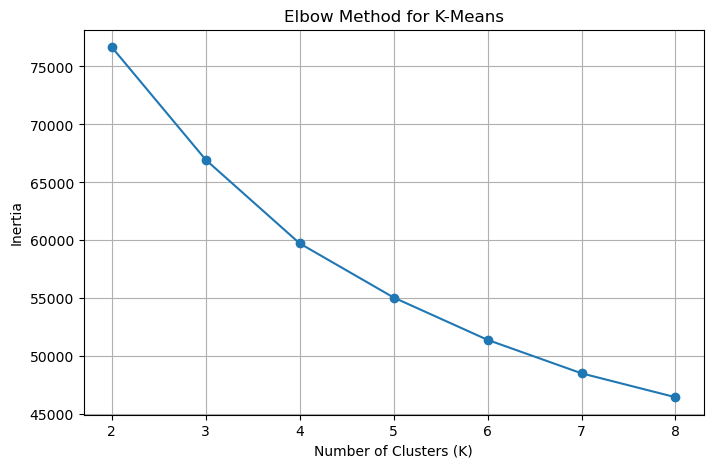

In [27]:
plt.figure(figsize=(8, 5))

plt.plot(
    k_results_df["k"],
    k_results_df["inertia"],
    marker="o"
)

plt.title("Elbow Method for K-Means")
plt.xlabel("Number of Clusters (K)")
plt.ylabel("Inertia")
plt.xticks(range(2, 9))
plt.grid(True)
plt.show()

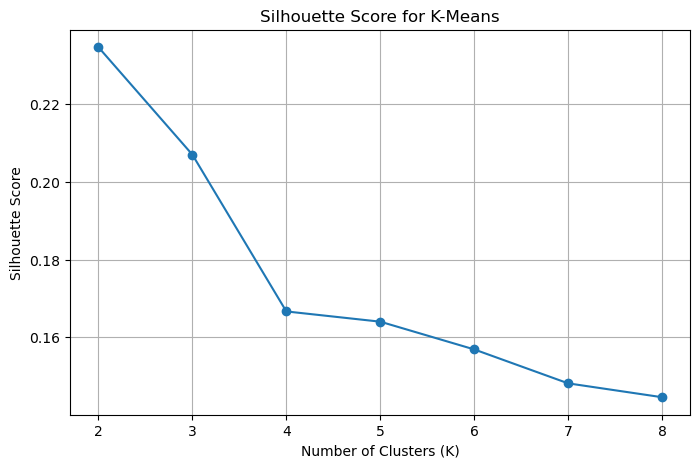

In [28]:
plt.figure(figsize=(8, 5))

plt.plot(
    k_results_df["k"],
    k_results_df["silhouette"],
    marker="o"
)

plt.title("Silhouette Score for K-Means")
plt.xlabel("Number of Clusters (K)")
plt.ylabel("Silhouette Score")
plt.xticks(range(2, 9))
plt.grid(True)
plt.show()

In [29]:
# ==============================
# FINAL K-MEANS MODEL
# ==============================

km = KMeans(
    n_clusters=3,
    n_init=10,
    random_state=42
)

cluster_labels = km.fit_predict(Z)

print("Cluster counts:")
print(pd.Series(cluster_labels).value_counts().sort_index())

Cluster counts:
0    6686
1    3337
2    4977
Name: count, dtype: int64


In [30]:
# Convert target classes to numeric labels
y_numeric = pd.factorize(y)[0]

ari = adjusted_rand_score(
    y_numeric,
    cluster_labels
)

print("ARI vs risk:", ari)

ARI vs risk: 0.27359744006837305


In [31]:
# Convert target classes to numeric labels
y_numeric = pd.factorize(y)[0]

ari = adjusted_rand_score(
    y_numeric,
    cluster_labels
)

print("ARI vs risk:", ari)

ARI vs risk: 0.27359744006837305


In [32]:
R["clustering"] = {
    "k": 3,
    "ARI": float(ari)
}

In [33]:
cluster_df = df[clin].copy()

cluster_df["cluster"] = cluster_labels

cluster_summary = (
    cluster_df
    .groupby("cluster")[clin]
    .mean()
    .round(2)
)

display(cluster_summary)

,age,bmi,fasting_blood_sugar,hba1c_level,blood_pressure_systolic,blood_pressure_diastolic,waist_circumference_cm
cluster,,,,,,,
0,39.44,20.57,143.82,6.34,133.14,82.79,93.79
1,46.65,22.29,213.39,7.87,140.53,86.07,97.95
2,49.36,26.92,172.43,6.93,147.34,91.04,110.34


In [34]:
# ==============================
# 9. FEATURE ENGINEERING
# ==============================

class DiabetesFeatureEngineer(
    BaseEstimator,
    TransformerMixin
):

    def fit(self, X, y=None):
        return self

    def transform(self, X):

        X = X.copy()

        # --------------------------
        # Glycaemic features
        # --------------------------

        X["eag_from_hba1c"] = (
            28.7 * X["hba1c_level"] - 46.7
        )

        X["fbs_minus_eag"] = (
            X["fasting_blood_sugar"]
            - X["eag_from_hba1c"]
        )

        X["fbs_hba1c_product"] = (
            X["fasting_blood_sugar"]
            * X["hba1c_level"]
        )

        X["fbs_ge_126"] = (
            X["fasting_blood_sugar"] >= 126
        ).astype(int)

        X["hba1c_ge_6_5"] = (
            X["hba1c_level"] >= 6.5
        ).astype(int)

        X["both_glycaemic_flags"] = (
            X["fbs_ge_126"]
            * X["hba1c_ge_6_5"]
        )

        # --------------------------
        # Blood pressure
        # --------------------------

        X["pulse_pressure"] = (
            X["blood_pressure_systolic"]
            - X["blood_pressure_diastolic"]
        )

        X["mean_arterial_pressure"] = (
            X["blood_pressure_diastolic"]
            + X["pulse_pressure"] / 3
        )

        X["hypertension_flag"] = (
            (X["blood_pressure_systolic"] >= 140)
            |
            (X["blood_pressure_diastolic"] >= 90)
        ).astype(int)

        # --------------------------
        # Adiposity
        # --------------------------

        X["waist_per_bmi"] = (
            X["waist_circumference_cm"]
            / X["bmi"]
        )

        X["bmi_overweight_asian"] = (
            X["bmi"] >= 23
        ).astype(int)

        X["bmi_obese_asian"] = (
            X["bmi"] >= 27.5
        ).astype(int)

        # --------------------------
        # Age and lifestyle
        # --------------------------

        X["age_x_bmi"] = (
            X["age"]
            * X["bmi"]
        )

        X["age_ge_45"] = (
            X["age"] >= 45
        ).astype(int)

        act = X["physical_activity_level"].map({
            "Active": 0,
            "Moderate": 1,
            "Sedentary": 2
        })

        fam = (
            X["family_history_diabetes"] == "Yes"
        ).astype(int)

        X["lifestyle_risk_score"] = (
            act
            + fam
            + X["bmi_overweight_asian"]
        )

        X["sleep_deviation"] = (
            X["hours_sleep_per_night"]
            - 7.5
        ).abs()

        return X

In [35]:
# Test feature engineering separately

fe = DiabetesFeatureEngineer()

X_engineered = fe.fit_transform(X)

print(
    "Original number of features:",
    X.shape[1]
)

print(
    "Number of features after engineering:",
    X_engineered.shape[1]
)

print("\nNew features:")

new_features = [
    col for col in X_engineered.columns
    if col not in X.columns
]

print(new_features)

Original number of features: 17
Number of features after engineering: 33

New features:
['eag_from_hba1c', 'fbs_minus_eag', 'fbs_hba1c_product', 'fbs_ge_126', 'hba1c_ge_6_5', 'both_glycaemic_flags', 'pulse_pressure', 'mean_arterial_pressure', 'hypertension_flag', 'waist_per_bmi', 'bmi_overweight_asian', 'bmi_obese_asian', 'age_x_bmi', 'age_ge_45', 'lifestyle_risk_score', 'sleep_deviation']


In [36]:
# ==============================
# 11. FEATURE TYPES
# ==============================

num_cols = [
    "age",
    "bmi",
    "fasting_blood_sugar",
    "hba1c_level",
    "blood_pressure_systolic",
    "blood_pressure_diastolic",
    "waist_circumference_cm",
    "hours_sleep_per_night"
]

print("Numerical columns:")
print(num_cols)

Numerical columns:
['age', 'bmi', 'fasting_blood_sugar', 'hba1c_level', 'blood_pressure_systolic', 'blood_pressure_diastolic', 'waist_circumference_cm', 'hours_sleep_per_night']


In [37]:
ordinal_maps = {

    "physical_activity_level":
        ["Active", "Moderate", "Sedentary"],

    "income_bracket":
        ["Low", "Middle", "High"],

    "smoking_status":
        ["Never", "Former", "Current"],

    "alcohol_consumption":
        ["Never", "Occasional", "Regular"]
}

In [38]:
nominal = [
    "gender",
    "diet_type",
    "family_history_diabetes",
    "city"
]

print("Nominal columns:")
print(nominal)

Nominal columns:
['gender', 'diet_type', 'family_history_diabetes', 'city']


In [39]:
# ==============================
# 12. PREPROCESSOR
# ==============================

def build_preprocessor(engineered=True):

    # Numerical variables
    num = list(num_cols)

    if engineered:

        num += [
            "eag_from_hba1c",
            "fbs_minus_eag",
            "fbs_hba1c_product",
            "pulse_pressure",
            "mean_arterial_pressure",
            "waist_per_bmi",
            "age_x_bmi",
            "lifestyle_risk_score",
            "sleep_deviation"
        ]

    # Binary engineered flags
    flags = [
        "fbs_ge_126",
        "hba1c_ge_6_5",
        "both_glycaemic_flags",
        "hypertension_flag",
        "bmi_overweight_asian",
        "bmi_obese_asian",
        "age_ge_45"
    ] if engineered else []

    # Ordinal variables
    ord_cols = list(ordinal_maps.keys())

    # Nominal variables
    nominal = [
        "gender",
        "diet_type",
        "family_history_diabetes",
        "city"
    ]

    preprocessor = ColumnTransformer(

        transformers=[

            # Numerical
            (
                "num",
                StandardScaler(),
                num
            ),

            # Binary flags
            (
                "flags",
                "passthrough",
                flags
            ),

            # Ordinal
            (
                "ord",
                Pipeline([
                    (
                        "imp",
                        SimpleImputer(
                            strategy="constant",
                            fill_value="Missing"
                        )
                    ),

                    (
                        "enc",
                        OrdinalEncoder(
                            categories=[
                                ordinal_maps[c] + ["Missing"]
                                for c in ord_cols
                            ]
                        )
                    )
                ]),
                ord_cols
            ),

            # Nominal
            (
                "nom",
                OneHotEncoder(
                    handle_unknown="ignore",
                    min_frequency=30
                ),
                nominal
            )
        ]
    )

    return preprocessor

In [40]:
# ==============================
# 13. MODEL PIPELINE
# ==============================

def make_pipe(
    clf,
    engineered=True
):

    steps = []

    # Feature engineering
    if engineered:

        steps.append(
            (
                "fe",
                DiabetesFeatureEngineer()
            )
        )

    # Preprocessing
    steps.append(
        (
            "prep",
            build_preprocessor(engineered)
        )
    )

    # Classifier
    steps.append(
        (
            "clf",
            clf
        )
    )

    return Pipeline(steps)

In [41]:
# ==============================
# 14. CROSS VALIDATION
# ==============================

cv = RepeatedStratifiedKFold(
    n_splits=5,
    n_repeats=2,
    random_state=SEED
)

scoring = {

    "accuracy": "accuracy",

    "bal_acc": "balanced_accuracy",

    "macro_f1": "f1_macro",

    "roc_auc": "roc_auc_ovr",

    "neg_logloss": "neg_log_loss"
}

In [42]:
# ==============================
# 15. CANDIDATE MODELS
# ==============================

candidates = {

    "Dummy (most frequent)":

        DummyClassifier(
            strategy="most_frequent"
        ),

    "Logistic Regression":

        LogisticRegression(
            max_iter=3000,
            random_state=SEED
        ),

    "Random Forest":

        RandomForestClassifier(
            n_estimators=200,
            min_samples_leaf=3,
            n_jobs=-1,
            random_state=SEED
        ),

    "Hist. Gradient Boosting":

        HistGradientBoostingClassifier(
            random_state=SEED
        )
}

In [43]:
# ==============================
# 16. MODEL COMPARISON
# ==============================

comparison_results = []

for name, clf in candidates.items():

    print("=" * 60)
    print("Model:", name)

    pipe = make_pipe(
        clf,
        engineered=True
    )

    scores = cross_validate(
        pipe,
        X_tr,
        y_tr,
        cv=cv,
        scoring=scoring,
        n_jobs=-1
    )

    result = {

        "Model": name,

        "Accuracy Mean":
            scores["test_accuracy"].mean(),

        "Accuracy Std":
            scores["test_accuracy"].std(),

        "Balanced Accuracy":
            scores["test_bal_acc"].mean(),

        "Macro F1":
            scores["test_macro_f1"].mean(),

        "ROC-AUC":
            scores["test_roc_auc"].mean(),

        "Log Loss":
            -scores["test_neg_logloss"].mean()
    }

    comparison_results.append(result)

    print(
        "Accuracy:",
        round(result["Accuracy Mean"], 4)
    )

    print(
        "Balanced Accuracy:",
        round(result["Balanced Accuracy"], 4)
    )

    print(
        "Macro F1:",
        round(result["Macro F1"], 4)
    )

    print(
        "ROC-AUC:",
        round(result["ROC-AUC"], 4)
    )

    print(
        "Log Loss:",
        round(result["Log Loss"], 4)
    )

Model: Dummy (most frequent)
Accuracy: 0.6
Balanced Accuracy: 0.3333
Macro F1: 0.25
ROC-AUC: 0.5
Log Loss: 14.4175
Model: Logistic Regression
Accuracy: 0.7903
Balanced Accuracy: 0.7275
Macro F1: 0.7389
ROC-AUC: 0.9176
Log Loss: 0.461
Model: Random Forest
Accuracy: 0.7882
Balanced Accuracy: 0.7253
Macro F1: 0.7385
ROC-AUC: 0.9144
Log Loss: 0.4718
Model: Hist. Gradient Boosting
Accuracy: 0.7814
Balanced Accuracy: 0.7194
Macro F1: 0.7306
ROC-AUC: 0.9096
Log Loss: 0.5029


In [44]:
# ==============================
# 16. MODEL COMPARISON
# ==============================

comparison_results = []

for name, clf in candidates.items():

    print("=" * 60)
    print("Model:", name)

    pipe = make_pipe(
        clf,
        engineered=True
    )

    scores = cross_validate(
        pipe,
        X_tr,
        y_tr,
        cv=cv,
        scoring=scoring,
        n_jobs=-1
    )

    result = {

        "Model": name,

        "Accuracy Mean":
            scores["test_accuracy"].mean(),

        "Accuracy Std":
            scores["test_accuracy"].std(),

        "Balanced Accuracy":
            scores["test_bal_acc"].mean(),

        "Macro F1":
            scores["test_macro_f1"].mean(),

        "ROC-AUC":
            scores["test_roc_auc"].mean(),

        "Log Loss":
            -scores["test_neg_logloss"].mean()
    }

    comparison_results.append(result)

    print(
        "Accuracy:",
        round(result["Accuracy Mean"], 4)
    )

    print(
        "Balanced Accuracy:",
        round(result["Balanced Accuracy"], 4)
    )

    print(
        "Macro F1:",
        round(result["Macro F1"], 4)
    )

    print(
        "ROC-AUC:",
        round(result["ROC-AUC"], 4)
    )

    print(
        "Log Loss:",
        round(result["Log Loss"], 4)
    )

Model: Dummy (most frequent)
Accuracy: 0.6
Balanced Accuracy: 0.3333
Macro F1: 0.25
ROC-AUC: 0.5
Log Loss: 14.4175
Model: Logistic Regression
Accuracy: 0.7903
Balanced Accuracy: 0.7275
Macro F1: 0.7389
ROC-AUC: 0.9176
Log Loss: 0.461
Model: Random Forest
Accuracy: 0.7882
Balanced Accuracy: 0.7253
Macro F1: 0.7385
ROC-AUC: 0.9144
Log Loss: 0.4718
Model: Hist. Gradient Boosting
Accuracy: 0.7814
Balanced Accuracy: 0.7194
Macro F1: 0.7306
ROC-AUC: 0.9096
Log Loss: 0.5029


In [45]:
comparison_df = pd.DataFrame(
    comparison_results
)

comparison_df = comparison_df.sort_values(
    by="Macro F1",
    ascending=False
)

display(
    comparison_df.round(4)
)

,Model,Accuracy Mean,Accuracy Std,Balanced Accuracy,Macro F1,ROC-AUC,Log Loss
1,Logistic Regression,0.7903,0.0079,0.7275,0.7389,0.9176,0.4610
2,Random Forest,0.7882,0.0072,0.7253,0.7385,0.9144,0.4718
3,Hist. Gradient Boosting,0.7814,0.0067,0.7194,0.7306,0.9096,0.5029
0,Dummy (most frequent),0.6000,0.0000,0.3333,0.2500,0.5000,14.4175


In [46]:
# ==============================
# 17. HYPERPARAMETER GRIDS
# ==============================

grids = {

    "Logistic Regression": {

        "clf__C": [
            0.01,
            0.1,
            1,
            10
        ]
    },

    "Hist. Gradient Boosting": {

        "clf__learning_rate": [
            0.05
        ],

        "clf__max_depth": [
            3,
            5
        ],

        "clf__l2_regularization": [
            1.0,
            10.0
        ],

        "clf__max_iter": [
            100
        ]
    }
}

In [47]:
# Inner CV for hyperparameter tuning
inner = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=1
)

# Outer CV for unbiased performance estimation
outer = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=2
)

In [48]:
# ==============================
# NESTED CROSS VALIDATION
# ==============================

nested = {}
tuned = {}

for name, grid in grids.items():

    print("=" * 60)
    print("Tuning:", name)

    # Create GridSearchCV
    gs = GridSearchCV(

        estimator=make_pipe(
            candidates[name],
            engineered=True
        ),

        param_grid=grid,

        cv=inner,

        scoring="f1_macro",

        n_jobs=-1
    )

    # Outer CV
    sc = cross_validate(

        gs,

        X_tr,
        y_tr,

        cv=outer,

        scoring={
            "macro_f1": "f1_macro",
            "accuracy": "accuracy",
            "roc_auc": "roc_auc_ovr"
        },

        n_jobs=1
    )

    # Fit GridSearch on complete training data
    gs.fit(
        X_tr,
        y_tr
    )

    tuned[name] = gs

    nested[name] = {

        "macro_f1": [
            float(
                sc["test_macro_f1"].mean()
            ),

            float(
                sc["test_macro_f1"].std()
            )
        ],

        "accuracy": [
            float(
                sc["test_accuracy"].mean()
            ),

            float(
                sc["test_accuracy"].std()
            )
        ],

        "roc_auc": [
            float(
                sc["test_roc_auc"].mean()
            ),

            float(
                sc["test_roc_auc"].std()
            )
        ]
    }

    nested[name]["best_params"] = {

        k.replace(
            "clf__",
            ""
        ): v

        for k, v
        in gs.best_params_.items()
    }

    print(
        "Best parameters:",
        gs.best_params_
    )

    print(
        "Nested Macro F1:",
        round(
            nested[name]["macro_f1"][0],
            4
        )
    )

    print(
        "Nested Accuracy:",
        round(
            nested[name]["accuracy"][0],
            4
        )
    )

    print(
        "Nested ROC-AUC:",
        round(
            nested[name]["roc_auc"][0],
            4
        )
    )

Tuning: Logistic Regression
Best parameters: {'clf__C': 0.1}
Nested Macro F1: 0.7404
Nested Accuracy: 0.7912
Nested ROC-AUC: 0.9175
Tuning: Hist. Gradient Boosting
Best parameters: {'clf__l2_regularization': 10.0, 'clf__learning_rate': 0.05, 'clf__max_depth': 3, 'clf__max_iter': 100}
Nested Macro F1: 0.7404
Nested Accuracy: 0.79
Nested ROC-AUC: 0.9159


In [49]:
# ==============================
# 19. SELECT FINAL MODEL
# ==============================

final_name = max(
    nested,
    key=lambda n:
        nested[n]["macro_f1"][0]
)

print(
    "Selected final model:",
    final_name
)

final = tuned[
    final_name
].best_estimator_

Selected final model: Hist. Gradient Boosting


In [50]:
# ==============================
# 19. SELECT FINAL MODEL
# ==============================

final_name = max(
    nested,
    key=lambda n:
        nested[n]["macro_f1"][0]
)

print(
    "Selected final model:",
    final_name
)

final = tuned[
    final_name
].best_estimator_

Selected final model: Hist. Gradient Boosting


In [51]:
# ==============================
# 21. FINAL PREDICTIONS
# ==============================

proba = final.predict_proba(
    X_te
)

pred = final.predict(
    X_te
)

print("Probability shape:", proba.shape)
print("Prediction shape:", pred.shape)

Probability shape: (3000, 3)
Prediction shape: (3000,)


In [52]:
pred_from_argmax = final.classes_[
    proba.argmax(axis=1)
]

print(
    np.array_equal(
        pred,
        pred_from_argmax
    )
)

True


In [53]:
# ==============================
# 22. FINAL EVALUATION
# ==============================

accuracy = accuracy_score(
    y_te,
    pred
)

balanced_accuracy = balanced_accuracy_score(
    y_te,
    pred
)

macro_f1 = f1_score(
    y_te,
    pred,
    average="macro"
)

weighted_f1 = f1_score(
    y_te,
    pred,
    average="weighted"
)

roc_auc = roc_auc_score(
    y_te,
    proba,
    multi_class="ovr"
)

logloss = log_loss(
    y_te,
    proba
)

kappa = cohen_kappa_score(
    y_te,
    pred
)

qw_kappa = cohen_kappa_score(
    y_te,
    pred,
    weights="quadratic"
)

In [54]:
# ==============================
# PRINT FINAL METRICS
# ==============================

print("=" * 60)
print("FINAL TEST SET PERFORMANCE")
print("=" * 60)

print(
    f"Accuracy:              {accuracy:.4f}"
)

print(
    f"Balanced Accuracy:     {balanced_accuracy:.4f}"
)

print(
    f"Macro F1:              {macro_f1:.4f}"
)

print(
    f"Weighted F1:           {weighted_f1:.4f}"
)

print(
    f"ROC-AUC (OvR):         {roc_auc:.4f}"
)

print(
    f"Log Loss:              {logloss:.4f}"
)

print(
    f"Cohen's Kappa:         {kappa:.4f}"
)

print(
    f"Quadratic Weighted Kappa: {qw_kappa:.4f}"
)

FINAL TEST SET PERFORMANCE
Accuracy:              0.7920
Balanced Accuracy:     0.7349
Macro F1:              0.7428
Weighted F1:           0.7896
ROC-AUC (OvR):         0.9122
Log Loss:              0.4750
Cohen's Kappa:         0.6192
Quadratic Weighted Kappa: 0.4710


In [55]:
# ==============================
# 23. CLASSIFICATION REPORT
# ==============================

print(
    classification_report(
        y_te,
        pred,
        digits=3
    )
)

              precision    recall  f1-score   support

        High      0.792     0.738     0.764       450
         Low      0.867     0.899     0.882      1800
    Moderate      0.597     0.568     0.582       750

    accuracy                          0.792      3000
   macro avg      0.752     0.735     0.743      3000
weighted avg      0.788     0.792     0.790      3000



In [56]:
print(
    classification_report(
        y_te,
        pred,
        labels=CLASSES,
        target_names=CLASSES,
        digits=3
    )
)

              precision    recall  f1-score   support

         Low      0.867     0.899     0.882      1800
      Medium      0.000     0.000     0.000         0
        High      0.792     0.738     0.764       450

   micro avg      0.853     0.867     0.860      2250
   macro avg      0.553     0.546     0.549      2250
weighted avg      0.852     0.867     0.859      2250



C:\Users\harsh\anaconda3\Lib\site-packages\sklearn\metrics\_classification.py:1879: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
C:\Users\harsh\anaconda3\Lib\site-packages\sklearn\metrics\_classification.py:1879: UndefinedMetricWarning: Recall is ill-defined and being set to 0.0 in labels with no true samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
C:\Users\harsh\anaconda3\Lib\site-packages\sklearn\metrics\_classification.py:1879: UndefinedMetricWarning: F-score is ill-defined and being set to 0.0 in labels with no true nor predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
C:\Users\harsh\anaconda3\Lib\

In [57]:
# ==============================
# 24. CONFUSION MATRIX
# ==============================

cm = confusion_matrix(
    y_te,
    pred
)

print("Confusion Matrix:")
print(cm)

Confusion Matrix:
[[ 332    8  110]
 [   4 1618  178]
 [  83  241  426]]
